<a href="https://colab.research.google.com/github/rushidhende06-pixel/Datasets/blob/main/K_means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K Means Clustering

In [1]:
path =r"https://raw.githubusercontent.com/rushidhende06-pixel/Datasets/refs/heads/main/Mall_Customers.csv"
import pandas as pd
df=pd.read_csv(path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Perform Basic Quality Check

In [2]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
df.shape

(200, 5)

In [4]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [5]:
df.isna().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [6]:
df.duplicated().sum()

np.int64(0)


Consider features required for X (Cluster formation)

X=age,income and spend

In [7]:
x=df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [8]:
x.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [9]:
x.columns=["Age","Income","Spending"]
x.head()

,Age,Income,Spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
).set_output(transform='pandas')

num_pipe

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [11]:
x_pre=num_pipe.fit_transform(x)
x_pre.head()

,Age,Income,Spending
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


K Mean Cluster

In [12]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=4)
model.fit(x_pre)


KMeans(n_clusters=4)

In [13]:
clusters4=model.predict(x_pre)
clusters4

array([3, 3, 3, 3, 3, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 3, 3, 1, 3, 3, 3,
       1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3,
       1, 3, 1, 3, 3, 3, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 3,
       1, 1, 3, 3, 1, 1, 1, 1, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 3,
       3, 1, 1, 3, 1, 1, 3, 3, 1, 3, 1, 3, 3, 1, 1, 3, 1, 3, 1, 1, 1, 1,
       1, 3, 2, 3, 3, 3, 1, 1, 1, 1, 3, 2, 0, 0, 2, 0, 2, 0, 1, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 1, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0], dtype=int32)


Evaluation Metric: Inertia

In [14]:
model.inertia_

205.22514747675913

In [15]:
pip install yellowbrick

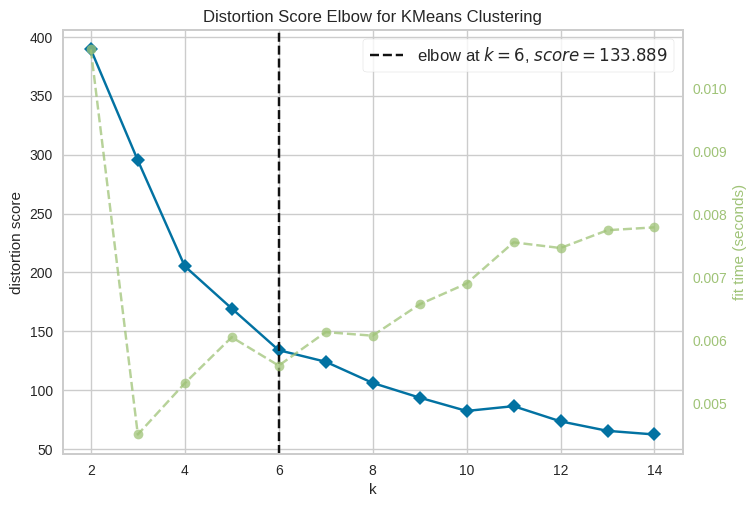

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [16]:
from yellowbrick.cluster import kelbow_visualizer
base_model=KMeans()
visualizer=kelbow_visualizer(base_model,x_pre,k=(2,15),timing=False)
visualizer.show()


In [17]:
final_model = KMeans(n_clusters=5)
final_model.fit(x_pre)

KMeans(n_clusters=5)

In [19]:
labels=final_model.predict(x_pre)
labels

array([0, 0, 3, 0, 0, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 1, 0, 3, 0,
       3, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 4, 0, 0, 0, 1, 1, 1, 1, 0, 4, 2, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 1, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2], dtype=int32)

In [20]:
df["Cluster Number"]= labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,3
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [21]:
df[df['Cluster Number']==3]

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
2,3,Female,20,16,6,3
6,7,Female,35,18,6,3
8,9,Male,64,19,3,3
10,11,Male,67,19,14,3
12,13,Female,58,20,15,3
14,15,Male,37,20,13,3
16,17,Female,35,21,35,3
18,19,Male,52,23,29,3
20,21,Male,35,24,35,3
22,23,Female,46,25,5,3


In [22]:
print("Customer groups")

for i in range(5):
  display(df[df['Cluster Number']==i])

Customer groups


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
5,6,Female,22,17,76,0
7,8,Female,23,18,94,0
9,10,Female,30,19,72,0
11,12,Female,35,19,99,0
13,14,Female,24,20,77,0
15,16,Male,22,20,79,0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
40,41,Female,65,38,35,1
46,47,Female,50,40,55,1
50,51,Female,49,42,52,1
53,54,Male,59,43,60,1
54,55,Female,50,43,45,1
55,56,Male,47,43,41,1
56,57,Female,51,44,50,1
57,58,Male,69,44,46,1
59,60,Male,53,46,46,1
60,61,Male,70,46,56,1


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
122,123,Female,40,69,58,2
123,124,Male,39,69,91,2
125,126,Female,31,70,77,2
127,128,Male,40,71,95,2
129,130,Male,38,71,75,2
131,132,Male,39,71,75,2
133,134,Female,31,72,71,2
135,136,Female,29,73,88,2
137,138,Male,32,73,73,2
139,140,Female,35,74,72,2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
2,3,Female,20,16,6,3
6,7,Female,35,18,6,3
8,9,Male,64,19,3,3
10,11,Male,67,19,14,3
12,13,Female,58,20,15,3
14,15,Male,37,20,13,3
16,17,Female,35,21,35,3
18,19,Male,52,23,29,3
20,21,Male,35,24,35,3
22,23,Female,46,25,5,3


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster Number
112,113,Female,38,64,42,4
121,122,Female,38,67,40,4
124,125,Female,23,70,29,4
126,127,Male,43,71,35,4
128,129,Male,59,71,11,4
130,131,Male,47,71,9,4
132,133,Female,25,72,34,4
134,135,Male,20,73,5,4
136,137,Female,44,73,7,4
138,139,Male,19,74,10,4


In [23]:
df.to_csv("ClusterResults.csv",index=False)